<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook4_Zeros_and_Outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick student-mat.csv

Saving student-mat.csv to student-mat.csv


{'student-mat.csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"service

In [2]:
# Upload the file into Colab
from google.colab import files
files.upload()   # student_encoded.csv

Saving student_encoded.csv to student_encoded.csv


{'student_encoded.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other\n0,0,18,1,1,0,4,4,2,2,0,1,0,0,0,1,1,0,0,4,3,4,1,1,3,6,5,6,6,0,0,0,0,0,0,0,1,0,0,0,1,0\n0,0,17,1,1,1,1,1,1,2,0,0,1,0,0,0,1,1,0,5,3,3,1,1,3,4,5,5,6,0,0,0,0,0,1,0,0,0,0,0,0,0\n0,0,15,1,0,1,1,1,1,2,3,1,0,1,0,1,1,1,0,4,3,2,2,3,3,10,7,8,10,0,0,0,0,0,1,0,0,0,1,0,1,0\n0,0,15,1,1,1,4,2,1,3,0,0,1,1,1,1,1,1,1,3,2,2,1,1,5,2,15,14,15,1,0,0,0,0,0,1,0,1,0,0,1,0\n0,0,16,1,1,1,3,3,1,2,0,0,1,1,0,1,1,0,0,4,3,2,1,2,5,4,6,10,10,0,1,0,0,0,1,0,0,1,0,0,0,0\n0,1,16,1,0,1,4,3,1,2,0,0,1,1,1,1,1,1,0,5,4,2,1,2,5,10,15,15,15,0,0,1,0,0,1,0,0,0,0,1,1,0\n0,1,16,1,0,1,2,2,1,2,0,0,0,0,0,1,1,1,0,4,4,4,1,1,3,0,12,12,11,0,1,0,0,

In [3]:
# Cell 1: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")           # original, readable
enc = pd.read_csv("student_encoded.csv")               # encoded, from Day 7
print(df.shape, enc.shape)

(395, 33) (395, 42)


In [4]:
# Cell 2: how many zero-grade students, and what do they look like?
df["zero_grade"] = (df["G3"] == 0)
print("Students with G3 = 0:", df["zero_grade"].sum(), "of", len(df))
print()
print(df[df["zero_grade"]][["G1", "G2", "G3", "absences", "failures"]].describe().round(2))

Students with G3 = 0: 38 of 395

          G1     G2    G3  absences  failures
count  38.00  38.00  38.0      38.0     38.00
mean    7.53   4.66   0.0       0.0      0.92
std     1.81   3.70   0.0       0.0      1.08
min     4.00   0.00   0.0       0.0      0.00
25%     6.00   0.00   0.0       0.0      0.00
50%     7.00   5.00   0.0       0.0      1.00
75%     9.00   8.00   0.0       0.0      1.75
max    12.00  10.00   0.0       0.0      3.00


In [5]:
# Cell 3: are zeros linked to a zero in G2? absences?
print("G2 = 0 vs G3 = 0:")
print(pd.crosstab(df["G2"] == 0, df["G3"] == 0, rownames=["G2 == 0"], colnames=["G3 == 0"]))
print()
print("Absences of zero-grade students:")
print(df[df["zero_grade"]]["absences"].value_counts().sort_index())
print()
print("Average absences, zero-grade vs others:")
print(df.groupby("zero_grade")["absences"].mean().round(2))

G2 = 0 vs G3 = 0:
G3 == 0  False  True 
G2 == 0              
False      357     25
True         0     13

Absences of zero-grade students:
absences
0    38
Name: count, dtype: int64

Average absences, zero-grade vs others:
zero_grade
False    6.32
True     0.00
Name: absences, dtype: float64


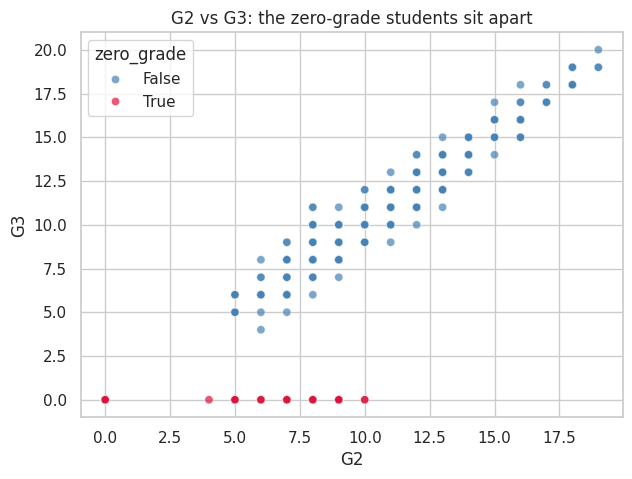

In [6]:
# Cell 4: see the zeros on the G2 vs G3 chart
plt.figure(figsize=(7, 5))
sns.scatterplot(x="G2", y="G3", hue="zero_grade", data=df, alpha=0.7,
                palette={False: "steelblue", True: "crimson"})
plt.title("G2 vs G3: the zero-grade students sit apart")
plt.savefig("zero_grade_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Cell 5: do zero-grade students differ on other features?
compare_cols = ["age", "failures", "studytime", "Medu", "Fedu", "goout", "G1"]
print(df.groupby("zero_grade")[compare_cols].mean().round(2).T)

zero_grade  False  True 
age         16.66  17.08
failures     0.27   0.92
studytime    2.04   1.97
Medu         2.80   2.32
Fedu         2.55   2.29
goout        3.10   3.21
G1          11.27   7.53


In [8]:
# Cell 6: absences outliers using the IQR rule
q1, q3 = df["absences"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, upper fence = {upper}")
print("Students above the fence:", (df["absences"] > upper).sum())
print("Largest absence counts:", sorted(df["absences"].unique())[-6:])
print()
print(df["absences"].describe().round(2))

Q1 = 0.0, Q3 = 8.0, IQR = 8.0, upper fence = 20.0
Students above the fence: 15
Largest absence counts: [np.int64(30), np.int64(38), np.int64(40), np.int64(54), np.int64(56), np.int64(75)]

count    395.00
mean       5.71
std        8.00
min        0.00
25%        0.00
50%        4.00
75%        8.00
max       75.00
Name: absences, dtype: float64


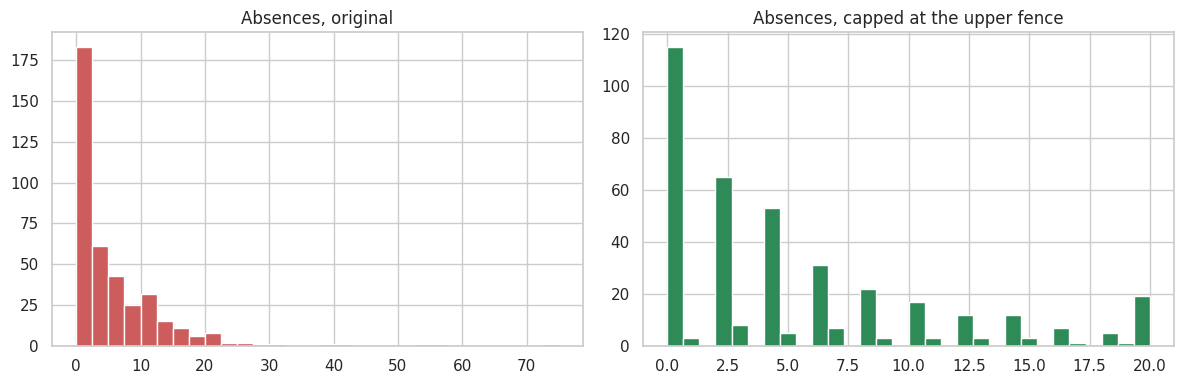

Correlation with G3 (original): 0.034
Correlation with G3 (capped)  : 0.068


In [9]:
# Cell 7: cap absences at the upper fence, and compare before/after
df["absences_capped"] = df["absences"].clip(upper=upper)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["absences"], bins=30, color="indianred", edgecolor="white")
axes[0].set_title("Absences, original")
axes[1].hist(df["absences_capped"], bins=30, color="seagreen", edgecolor="white")
axes[1].set_title("Absences, capped at the upper fence")
plt.tight_layout()
plt.savefig("absences_capping.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation with G3 (original):", round(df["absences"].corr(df["G3"]), 3))
print("Correlation with G3 (capped)  :", round(df["absences_capped"].corr(df["G3"]), 3))

In [10]:
# Cell 8: other outlier candidates, look but do not change
for c in ["age", "failures", "traveltime"]:
    print(f"{c:10s}", df[c].value_counts().sort_index().to_dict())

age        {15: 82, 16: 104, 17: 98, 18: 82, 19: 24, 20: 3, 21: 1, 22: 1}
failures   {0: 312, 1: 50, 2: 17, 3: 16}
traveltime {1: 257, 2: 107, 3: 23, 4: 8}


In [11]:
# Cell 9: does the zero-grade decision really matter? A fair test.
# Both training choices are scored on the SAME test students (graded ones only).
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

X = enc.drop(columns="G3")
y = enc["G3"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

graded = y_test > 0
X_test_g, y_test_g = X_test[graded], y_test[graded]

rows = []
for train_name, mask in [("train WITH zeros", y_train >= 0),
                         ("train WITHOUT zeros", y_train > 0)]:
    for feat_name, drop in [("all features", []),
                            ("without G1, G2", ["G1", "G2"])]:
        model = LinearRegression().fit(X_train[mask].drop(columns=drop), y_train[mask])
        pred = model.predict(X_test_g.drop(columns=drop))
        rows.append({
            "training data": train_name,
            "features": feat_name,
            "RMSE": round(np.sqrt(mean_squared_error(y_test_g, pred)), 2),
            "MAE": round(mean_absolute_error(y_test_g, pred), 2),
        })

pd.DataFrame(rows)

,training data,features,RMSE,MAE
0,train WITH zeros,all features,1.65,1.31
1,train WITH zeros,"without G1, G2",3.62,3.02
2,train WITHOUT zeros,all features,0.93,0.73
3,train WITHOUT zeros,"without G1, G2",3.14,2.61


In [12]:
# Cell 10: build and save the cleaned dataset
clean = enc[enc["G3"] > 0].copy()
clean["absences"] = clean["absences"].clip(upper=upper)

print("Original rows:", len(enc))
print("Rows removed (G3 = 0):", len(enc) - len(clean))
print("Clean shape:", clean.shape)
print("Absences max now:", clean["absences"].max())

clean.to_csv("student_clean.csv", index=False)

Original rows: 395
Rows removed (G3 = 0): 38
Clean shape: (357, 42)
Absences max now: 20
